In [34]:


import uproot

f = uproot.open("nue_cc_multidom/part_0000_hits.root")
ph = f["PhotonHits"]
print(ph.num_entries, "entries")
ph.show()         

g =  uproot.open("nue_nc_multidom/part_0000_hits.root")
phg = g["PhotonHits"]


173908 entries
name                 | typename                 | interpretation                
---------------------+--------------------------+-------------------------------
eventID              | int32_t                  | AsDtype('>i4')
hitTime              | double                   | AsDtype('>f8')
entryTime            | double                   | AsDtype('>f8')
flightTime           | double                   | AsDtype('>f8')
pathLenght           | double                   | AsDtype('>f8')
generationDetecti... | double                   | AsDtype('>f8')
energy               | double                   | AsDtype('>f8')
PMTnr                | int32_t                  | AsDtype('>i4')
moduleID             | int32_t                  | AsDtype('>i4')
dir_x                | double                   | AsDtype('>f8')
dir_y                | double                   | AsDtype('>f8')
dir_z                | double                   | AsDtype('>f8')
localPos_x           | double              

In [17]:
for name, cls in f.classnames().items():
    if cls == "TTree":
        t = f[name]
        print(f"\n=== {name}: {t.num_entries} entries")
        t.show()    # branch name, C++ type, interpretation


=== PhotonHits;1: 173908 entries
name                 | typename                 | interpretation                
---------------------+--------------------------+-------------------------------
eventID              | int32_t                  | AsDtype('>i4')
hitTime              | double                   | AsDtype('>f8')
entryTime            | double                   | AsDtype('>f8')
flightTime           | double                   | AsDtype('>f8')
pathLenght           | double                   | AsDtype('>f8')
generationDetecti... | double                   | AsDtype('>f8')
energy               | double                   | AsDtype('>f8')
PMTnr                | int32_t                  | AsDtype('>i4')
moduleID             | int32_t                  | AsDtype('>i4')
dir_x                | double                   | AsDtype('>f8')
dir_y                | double                   | AsDtype('>f8')
dir_z                | double                   | AsDtype('>f8')
localPos_x           | d

In [41]:
import awkward as ak
arr = ph.arrays()
b = {k: ak.to_numpy(ak.flatten(arr[k], axis=None)) for k in arr.fields}

arr2 = phg.arrays()
b2 = {k2: ak.to_numpy(ak.flatten(arr2[k2], axis=None)) for k2 in arr2.fields}

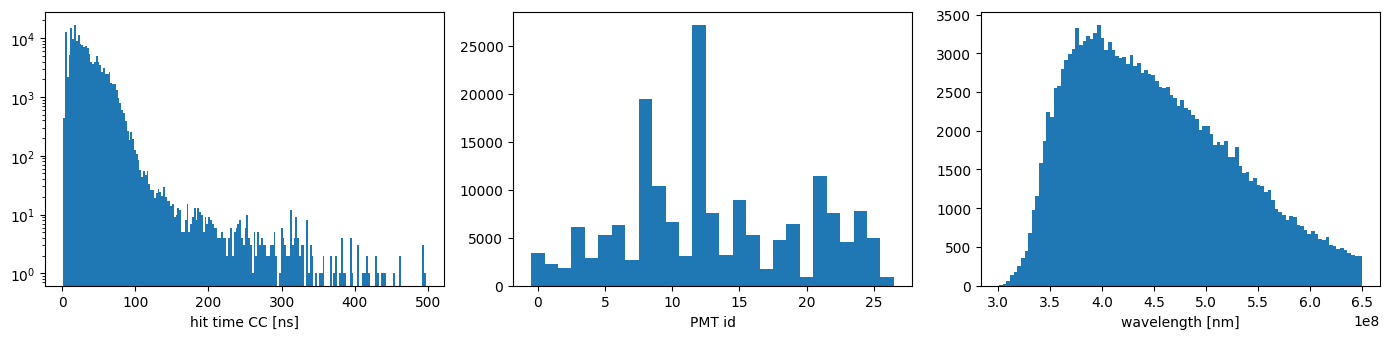

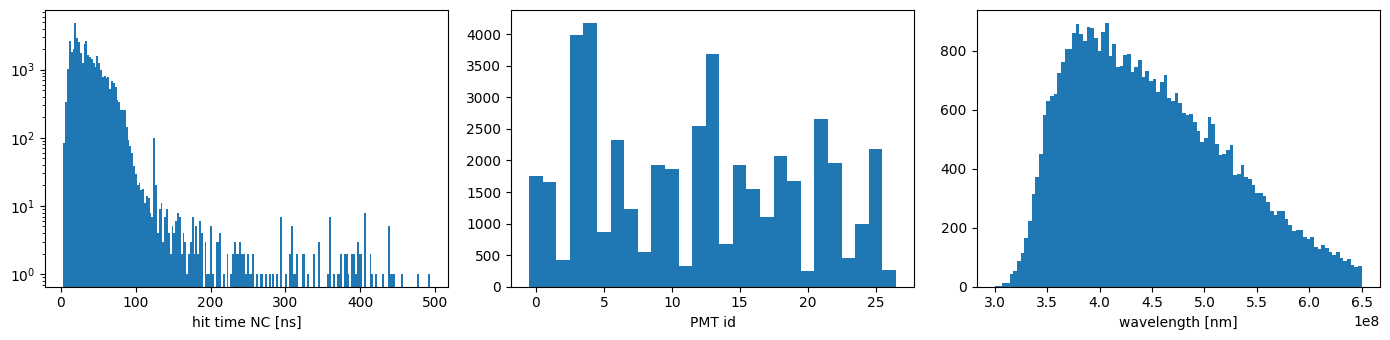

In [45]:
import matplotlib.pyplot as plt
import awkward as ak
import numpy as np

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(b["hitTime"], bins=200, log=True);          ax[0].set_xlabel("hit time CC [ns]")
ax[1].hist(b["moduleID"], bins=np.arange(b["moduleID"].max()+2)-0.5); ax[1].set_xlabel("PMT id")
ax[2].hist(1239.84/b["energy"] if b["energy"].max() < 20 else b["energy"], bins=100)
ax[2].set_xlabel("wavelength [nm]")
plt.tight_layout()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(b2["hitTime"], bins=200, log=True);          ax[0].set_xlabel("hit time NC [ns]")
ax[1].hist(b2["moduleID"], bins=np.arange(b2["moduleID"].max()+2)-0.5); ax[1].set_xlabel("PMT id")
ax[2].hist(1239.84/b2["energy"] if b2["energy"].max() < 20 else b2["energy"], bins=100)
ax[2].set_xlabel("wavelength [nm]")
plt.tight_layout()

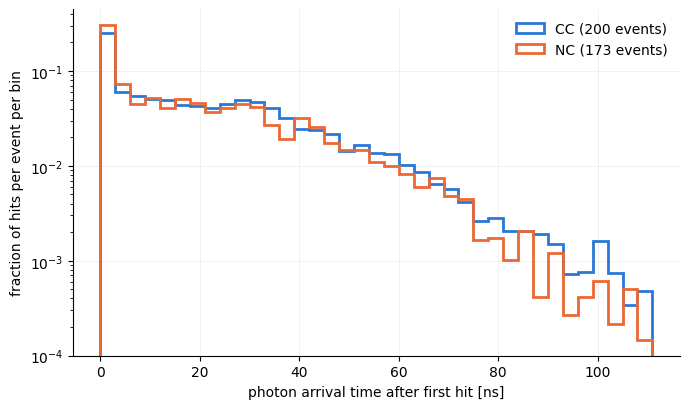

In [57]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def prep(d):
    df = pd.DataFrame({k: d[k] for k in ["eventID", "hitTime", "moduleID", "PMTnr"]})
    df["t_rel"] = df.hitTime - df.groupby("eventID").hitTime.transform("min")   # time after event's first hit
    df["w"] = 1.0 / df.groupby("eventID").hitTime.transform("size")             # each event weighs 1
    return df

data = {"CC": prep(b), "NC": prep(b2)}
COLORS = {"CC": "#2a78d6", "NC": "#eb6834"}

tmax = np.percentile(np.concatenate([d.t_rel for d in data.values()]), 99.5)
bins = np.arange(0, tmax + 3, 3) 

fig, ax = plt.subplots(figsize=(7, 4.2))
for c, d in data.items():
    n_ev = d.eventID.nunique()
    ax.hist(d.t_rel, bins=bins, weights=d.w / n_ev, histtype="step", lw=2,
            color=COLORS[c], label=f"{c} ({n_ev} events)")
ax.set_yscale("log")
ax.set_xlabel("photon arrival time after first hit [ns]")
ax.set_ylabel("fraction of hits per event per bin")
ax.legend(frameon=False); ax.grid(alpha=0.25, lw=0.5)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()

             CC    NC
moduleID             
12        27107  2545
8         19412   552
21        11452  2664
9         10416  1925
15         8958  1928
24         7757   989
22         7606  1961
13         7547  3683
10         6631  1857
19         6464  1675


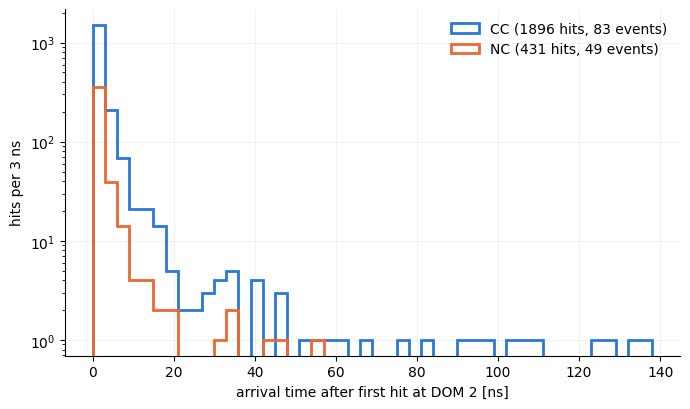

In [72]:
# hits per module in each sample, to pick one
counts = pd.concat({c: d.moduleID.value_counts() for c, d in data.items()}, axis=1).fillna(0)
print(counts.sort_values("CC", ascending=False).head(10))

DOM = 2
fig, ax = plt.subplots(figsize=(7, 4.2))
for c, d in data.items():
    dd = d[d.moduleID == DOM].copy()
    if dd.empty:
        continue
    dd["t_dom"] = dd.hitTime - dd.groupby("eventID").hitTime.transform("min")
    n_ev = dd.eventID.nunique()
    ax.hist(dd.t_dom, bins=np.arange(0, np.percentile(dd.t_dom, 99.5) + 3, 3),
            histtype="step", lw=2, color=COLORS[c],
            label=f"{c} ({len(dd)} hits, {n_ev} events)")
ax.set_yscale("log")
ax.set_xlabel(f"arrival time after first hit at DOM {DOM} [ns]")
ax.set_ylabel("hits per 3 ns")
ax.legend(frameon=False); ax.grid(alpha=0.25, lw=0.5)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()

In [77]:
ev = {c: uproot.open(t.file.file_path)["Events"].arrays(["eventID", "vx", "vy", "vz"], library="pd")
      for c, t in [("CC", ph), ("NC", phg)]}
ev["CC"].head()

,eventID,vx,vy,vz
0,36,5.337058,5.094336,-3.645925
1,39,-0.399732,-3.875254,2.133783
2,37,-2.684870,-2.998578,-5.842980
3,3,2.030299,-0.888102,0.696380
4,27,2.080165,0.398959,-1.834700


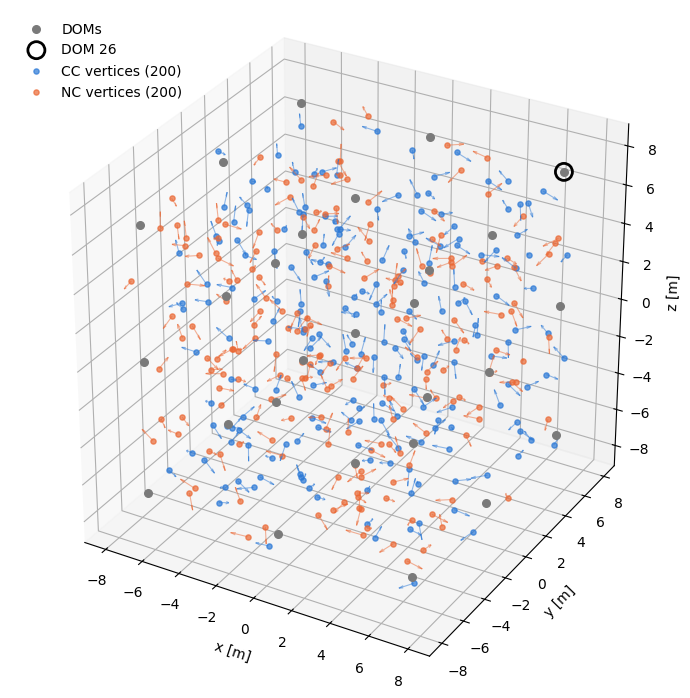

In [78]:
import uproot, numpy as np, pandas as pd, matplotlib.pyplot as plt

COLORS = {"CC": "#2a78d6", "NC": "#eb6834"}
DOM = 26

# event vertices [m] + neutrino directions, from each file's Events tree
ev = {c: uproot.open(t.file.file_path)["Events"].arrays(
          ["eventID", "vx", "vy", "vz", "nu_dx", "nu_dy", "nu_dz"], library="pd")
      for c, t in [("CC", ph), ("NC", phg)]}

# DOM centres = mean hit position per module (mm -> m)
hits = pd.concat([pd.DataFrame({k: d[k] for k in ["moduleID", "globalPos_x", "globalPos_y", "globalPos_z"]})
                  for d in (b, b2)])
doms = hits.groupby("moduleID")[["globalPos_x", "globalPos_y", "globalPos_z"]].mean() / 1000.0
doms.columns = ["x", "y", "z"]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
ax.scatter(doms.x, doms.y, doms.z, s=30, c="#7a7a7a", depthshade=False, label="DOMs")
if DOM in doms.index:
    r = doms.loc[DOM]
    ax.scatter(r.x, r.y, r.z, s=150, facecolors="none", edgecolors="black", lw=2, label=f"DOM {DOM}")
for c, e in ev.items():
    ax.scatter(e.vx, e.vy, e.vz, s=14, alpha=0.7, color=COLORS[c], depthshade=False, label=f"{c} vertices ({len(e)})")
    L = 0.05 * np.ptp(np.r_[doms.x, e.vx])          # arrow length ~5% of the scene
    ax.quiver(e.vx, e.vy, e.vz, e.nu_dx, e.nu_dy, e.nu_dz, length=L, color=COLORS[c], alpha=0.5, lw=0.8)
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")
ax.set_box_aspect((np.ptp(doms.x) or 1, np.ptp(doms.y) or 1, np.ptp(doms.z) or 1))   # true proportions
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

In [81]:
e = ev["CC"]
print(np.linalg.norm(e[["nu_dx","nu_dy","nu_dz"]], axis=1)[:5])   # should be 1

[1. 1. 1. 1. 1.]


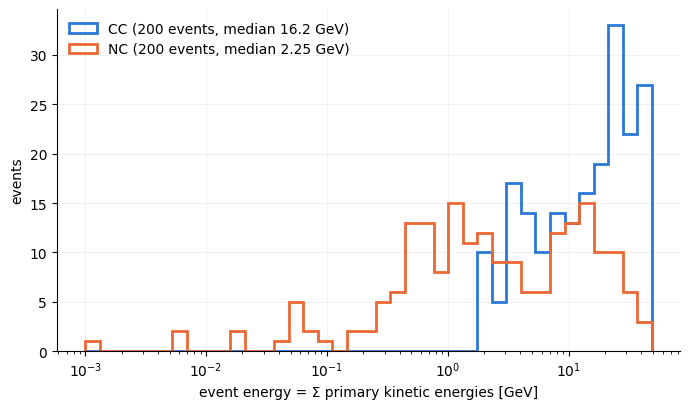

In [87]:


COLORS = {"CC": "#2a78d6", "NC": "#eb6834"}
ev = {c: uproot.open(t.file.file_path)["Events"].arrays(
          ["eventID", "primaryEnergy", "primaryParticle"], library="pd")
      for c, t in [("CC", ph), ("NC", phg)]}

allE = np.concatenate([e.primaryEnergy for e in ev.values()])
bins = np.logspace(np.log10(allE[allE > 0].min()), np.log10(allE.max()), 40)

fig, ax = plt.subplots(figsize=(7, 4.2))
for c, e in ev.items():
    ax.hist(e.primaryEnergy, bins=bins, histtype="step", lw=2, color=COLORS[c],
            label=f"{c} ({len(e)} events, median {e.primaryEnergy.median():.3g} GeV)")
ax.set_xscale("log")
ax.set_xlabel("event energy = Σ primary kinetic energies [GeV]")
ax.set_ylabel("events")
ax.legend(frameon=False); ax.grid(alpha=0.25, lw=0.5)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()

In [103]:
p =  uproot.open("nu_cc_big/part_0000_hits.root")

for name, cls in p.classnames().items():
    if cls == "TTree":
        t = p[name]
        print(f"\n=== {name}: {t.num_entries} entries")
        t.show()    

tracks = p["PhotonTracks"]


=== PhotonTracks;15: 626413 entries
name                 | typename                 | interpretation                
---------------------+--------------------------+-------------------------------
eventID              | int32_t                  | AsDtype('>i4')
trackID              | int32_t                  | AsDtype('>i4')
parentID             | int32_t                  | AsDtype('>i4')
particle             | TString                  | AsStrings()
creator              | TString                  | AsStrings()
energy               | double                   | AsDtype('>f8')
wavelength           | double                   | AsDtype('>f8')
detected             | int32_t                  | AsDtype('>i4')
x                    | std::vector<float>       | AsJagged(AsDtype('>f4'), he...
y                    | std::vector<float>       | AsJagged(AsDtype('>f4'), he...
z                    | std::vector<float>       | AsJagged(AsDtype('>f4'), he...
t                    | std::vector<float>   

In [ ]:
tracks[]